# Review 2 — Clustering Track: Customer Personality Analysis
**Dataset:** `marketing_campaign.csv` . 
**Goal:** discover customer segments using behaviour and demographic features without using campaign-response labels during fitting. Required algorithms: K-Means and Agglomerative Hierarchical Clustering. Required outputs: Elbow curve, dendrogram, Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, PCA 2D plot for both algorithms, and a t-SNE plot for at least one algorithm.

## 1. Imports and reproducibility

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram
sns.set_theme(style='whitegrid')
RANDOM_STATE=42
pd.set_option('display.max_columns',100)

## 2. Load and audit the dataset

In [2]:
import pandas as pd
df=pd.read_csv('marketing_campaign.csv')
print('Shape:', df.shape, '| Duplicate rows:', df.duplicated().sum())
display(df.head())
display(pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_%': (100 * df.isna().mean()).round(2)
}))
print('Columns:', df.columns.tolist())

Loaded dataset from: marketing_campaign.csv
Shape: (2240, 29) | Duplicate rows: 0


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


,dtype,missing,missing_%
ID,int64,0,0.00
Year_Birth,int64,0,0.00
Education,str,0,0.00
Marital_Status,str,0,0.00
Income,float64,24,1.07
Kidhome,int64,0,0.00
Teenhome,int64,0,0.00
Dt_Customer,str,0,0.00
Recency,int64,0,0.00
MntWines,int64,0,0.00


Columns: ['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


## 3. EDA — missing values and key customer distributions

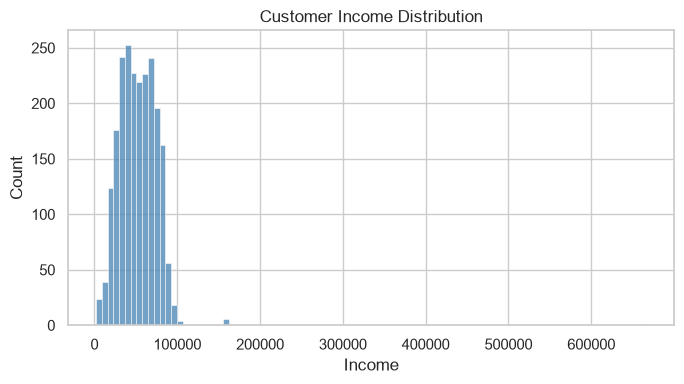

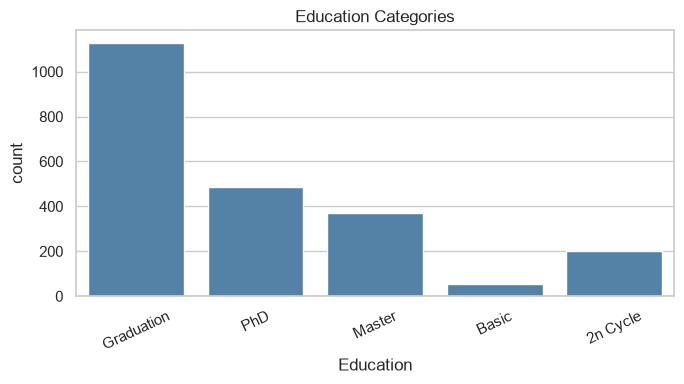

,Total recorded spend
MntWines,680816
MntMeatProducts,373968
MntGoldProds,98609
MntFishProducts,84057
MntSweetProducts,60621
MntFruits,58917


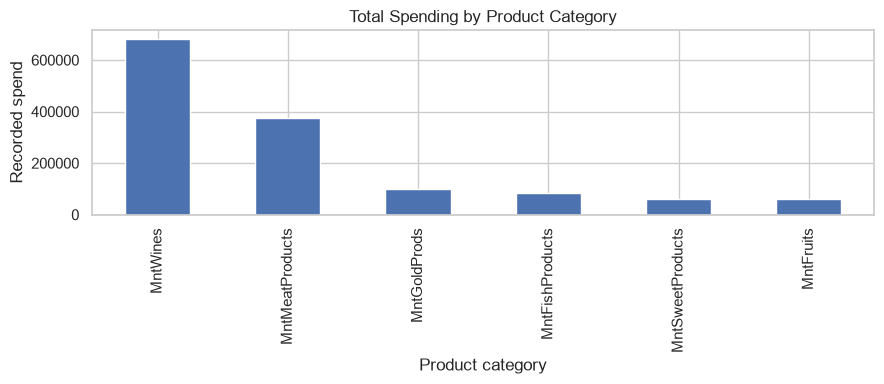

In [3]:
if 'Income' in df:
    plt.figure(figsize=(7,4)); sns.histplot(df['Income'],kde=False,color='steelblue'); plt.title('Customer Income Distribution'); plt.xlabel('Income'); plt.tight_layout(); plt.show()
if 'Education' in df:
    plt.figure(figsize=(7,4)); sns.countplot(data=df,x='Education',color='steelblue'); plt.title('Education Categories'); plt.xticks(rotation=25); plt.tight_layout(); plt.show()
spend_cols=[c for c in ['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds'] if c in df.columns]
if spend_cols:
    spend_summary=df[spend_cols].sum().sort_values(ascending=False)
    display(spend_summary.rename('Total recorded spend').to_frame())
    spend_summary.plot(kind='bar',figsize=(9,4),title='Total Spending by Product Category')
    plt.xlabel('Product category'); plt.ylabel('Recorded spend'); plt.tight_layout(); plt.show()

## 4. Feature engineering and unsupervised feature selection
Create age, total spend, household size and total purchase count where source columns are available. Exclude identifiers, customer enrolment date, and campaign response/acceptance outcomes from clustering. This keeps the algorithm focused on customer profile and behaviour rather than known campaign outcomes. No ground-truth labels are used in model fitting.

In [4]:
data=df.copy()
if 'Year_Birth' in data.columns: data['Age']=2026-data['Year_Birth']
spend_cols=[c for c in ['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds'] if c in data.columns]
purchase_cols=[c for c in ['NumWebPurchases','NumCatalogPurchases','NumStorePurchases','NumDealsPurchases'] if c in data.columns]
if spend_cols: data['TotalSpend']=data[spend_cols].sum(axis=1)
if purchase_cols: data['TotalPurchases']=data[purchase_cols].sum(axis=1)
if {'Kidhome','Teenhome'}.issubset(data.columns): data['HouseholdChildren']=data['Kidhome']+data['Teenhome']
exclude=[c for c in ['ID','Year_Birth','Dt_Customer','Response','AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4','AcceptedCmp5','Complain','Z_CostContact','Z_Revenue'] if c in data.columns]
features=data.drop(columns=exclude)
# Remove rows/columns that carry no usable variation.
features=features.loc[:,features.nunique(dropna=True)>1]
print('Excluded from fitting:',exclude)
print('Feature shape:',features.shape)
display(features.head())

Excluded from fitting: ['ID', 'Year_Birth', 'Dt_Customer', 'Response', 'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Complain', 'Z_CostContact', 'Z_Revenue']
Feature shape: (2240, 21)


,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,TotalSpend,TotalPurchases,HouseholdChildren
0,Graduation,Single,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,69,1617,25,0
1,Graduation,Single,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,72,27,6,2
2,Graduation,Together,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,61,776,21,0
3,Graduation,Together,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,42,53,8,1
4,PhD,Married,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,45,422,19,1


## 5. Preprocess numeric and categorical features

In [5]:
numeric_cols=features.select_dtypes(include=np.number).columns.tolist()
categorical_cols=features.select_dtypes(exclude=np.number).columns.tolist()
numeric_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
categorical_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
preprocessor=ColumnTransformer([('numeric',numeric_pipe,numeric_cols),('categorical',categorical_pipe,categorical_cols)],remainder='drop')
X=preprocessor.fit_transform(features)
feature_names=preprocessor.get_feature_names_out()
X=pd.DataFrame(X,columns=feature_names,index=features.index)
print('Processed matrix:',X.shape,'| All finite:',np.isfinite(X.to_numpy()).all())

Processed matrix: (2240, 32) | All finite: True


## 6. Elbow curve for K-Means

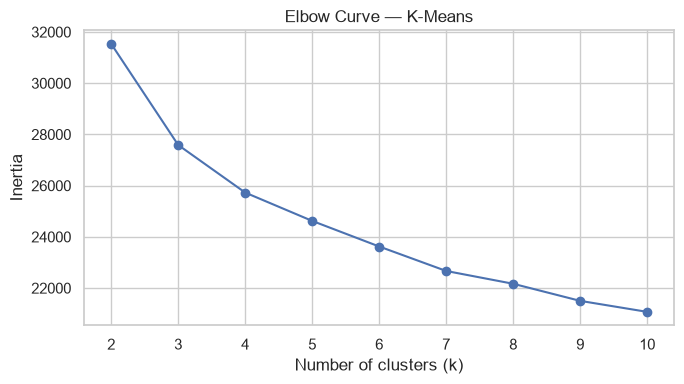

,Silhouette Score
k,
2,0.297310
3,0.224767
4,0.158930
5,0.156526
6,0.145847
7,0.144994
8,0.141387


Selected k (highest silhouette among k=2..8): 2


In [6]:
inertias=[]
k_values=range(2,11)
for k in k_values:
    km=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)
plt.figure(figsize=(7,4)); plt.plot(list(k_values),inertias,marker='o')
plt.title('Elbow Curve — K-Means'); plt.xlabel('Number of clusters (k)'); plt.ylabel('Inertia')
plt.xticks(list(k_values)); plt.tight_layout(); plt.show()
# Select k by best silhouette among a reasonable candidate range; also inspect the elbow plot.
sil_by_k={}
for k in range(2,9):
    labels=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=10).fit_predict(X)
    sil_by_k[k]=silhouette_score(X,labels)
display(pd.Series(sil_by_k,name='Silhouette Score').rename_axis('k').to_frame())
best_k=max(sil_by_k,key=sil_by_k.get)
print('Selected k (highest silhouette among k=2..8):',best_k)

## 7. Dendrogram for hierarchical clustering

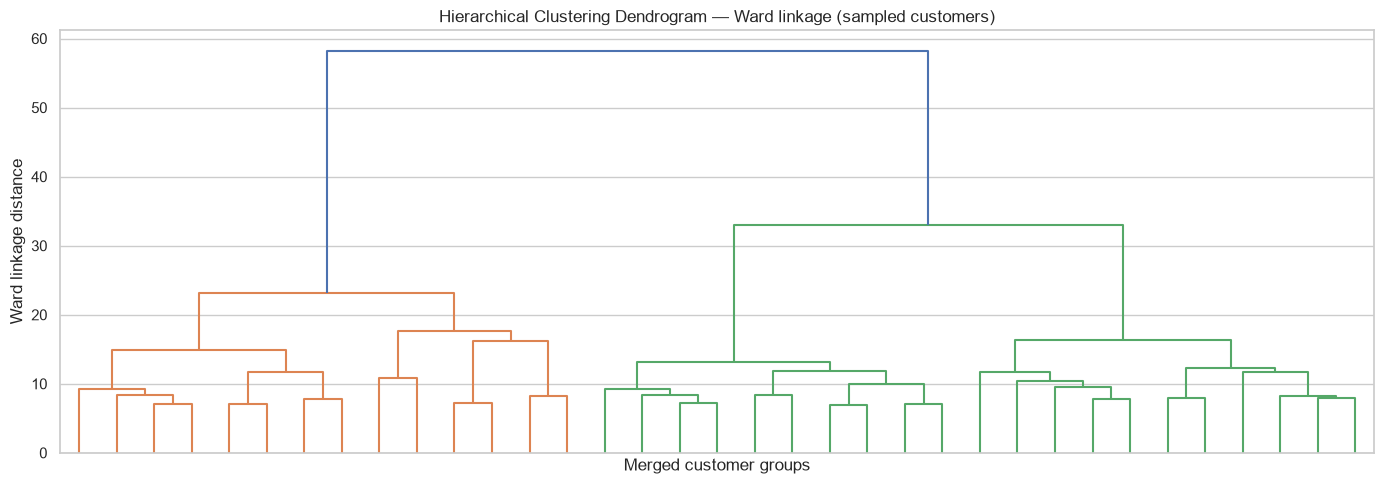

In [7]:
# Dendrogram is sampled for readability and practical runtime.
sample_n=min(300,len(X))
sample_X=X.sample(n=sample_n,random_state=RANDOM_STATE)
Z=linkage(sample_X,method='ward')
plt.figure(figsize=(14,5))
dendrogram(Z,no_labels=True,truncate_mode='lastp',p=35,show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram — Ward linkage (sampled customers)')
plt.xlabel('Merged customer groups'); plt.ylabel('Ward linkage distance')
plt.tight_layout(); plt.show()

In [8]:
# Compare linkage strategies using the same selected k.
# Some linkage methods can create degenerate partitions (e.g., one customer in a
# cluster and almost everyone else in the other). We report cluster sizes and do
# not present internal scores for those partitions as meaningful comparisons.
linkage_rows = []
min_cluster_fraction = 0.01
min_cluster_size = max(2, int(np.ceil(min_cluster_fraction * len(X))))

for strategy in ['ward', 'complete', 'average']:
    labels = AgglomerativeClustering(n_clusters=best_k, linkage=strategy).fit_predict(X)
    counts = pd.Series(labels).value_counts()
    smallest_cluster = int(counts.min())
    degenerate = smallest_cluster < min_cluster_size

    row = {
        'Linkage': strategy,
        'Cluster sizes': ', '.join(str(int(v)) for v in counts.sort_index().values),
        'Smallest cluster': smallest_cluster,
        'Degenerate partition?': 'Yes — interpret cautiously' if degenerate else 'No'
    }
    if degenerate:
        row.update({
            'Silhouette Score': np.nan,
            'Davies-Bouldin Index': np.nan,
            'Calinski-Harabasz Index': np.nan
        })
    else:
        row.update({
            'Silhouette Score': silhouette_score(X, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X, labels),
            'Calinski-Harabasz Index': calinski_harabasz_score(X, labels)
        })
    linkage_rows.append(row)

linkage_comparison = pd.DataFrame(linkage_rows)
display(linkage_comparison.round(4))
print(f'Partitions with a cluster smaller than {min_cluster_size} customers '
      f'({min_cluster_fraction:.0%} of the dataset) are flagged as degenerate; '
      'their internal validation scores are omitted rather than treated as evidence of good clustering.')

,Linkage,Cluster sizes,Smallest cluster,Degenerate partition?,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,"1131, 1109",1109,No,0.257,1.5122,861.3075
1,complete,"2239, 1",1,Yes — interpret cautiously,NaN,NaN,NaN
2,average,"2239, 1",1,Yes — interpret cautiously,NaN,NaN,NaN


Partitions with a cluster smaller than 23 customers (1% of the dataset) are flagged as degenerate; their internal validation scores are omitted rather than treated as evidence of good clustering.


## 8. Fit both required clustering algorithms

In [9]:
kmeans=KMeans(n_clusters=best_k,random_state=RANDOM_STATE,n_init=10)
kmeans_labels=kmeans.fit_predict(X)
# Ward linkage is appropriate for Euclidean distance on the standardised representation.
hierarchical=AgglomerativeClustering(n_clusters=best_k,linkage='ward')
hierarchical_labels=hierarchical.fit_predict(X)
cluster_labels={'K-Means':kmeans_labels,'Agglomerative (Ward)':hierarchical_labels}
for name,labels in cluster_labels.items():
    print(name,'cluster sizes:')
    display(pd.Series(labels).value_counts().sort_index().rename('customers').to_frame())

K-Means cluster sizes:


,customers
0,932
1,1308


Agglomerative (Ward) cluster sizes:


,customers
0,1131
1,1109


## 9. Evaluation metrics for every clustering algorithm

In [10]:
metric_rows=[]
for name,labels in cluster_labels.items():
    metric_rows.append({'Algorithm':name,'Silhouette Score':silhouette_score(X,labels),
                        'Davies-Bouldin Index':davies_bouldin_score(X,labels),
                        'Calinski-Harabasz Index':calinski_harabasz_score(X,labels)})
cluster_metrics=pd.DataFrame(metric_rows)
display(cluster_metrics.round(4))
print('Higher silhouette and Calinski-Harabasz are generally preferred; lower Davies-Bouldin is generally preferred.')

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.2973,1.4324,1003.3014
1,Agglomerative (Ward),0.2570,1.5122,861.3075


Higher silhouette and Calinski-Harabasz are generally preferred; lower Davies-Bouldin is generally preferred.


## 10. PCA 2D visualisation for each algorithm

PCA explained variance ratio: [0.3888 0.1229]
Total variance shown in 2D: 0.5117


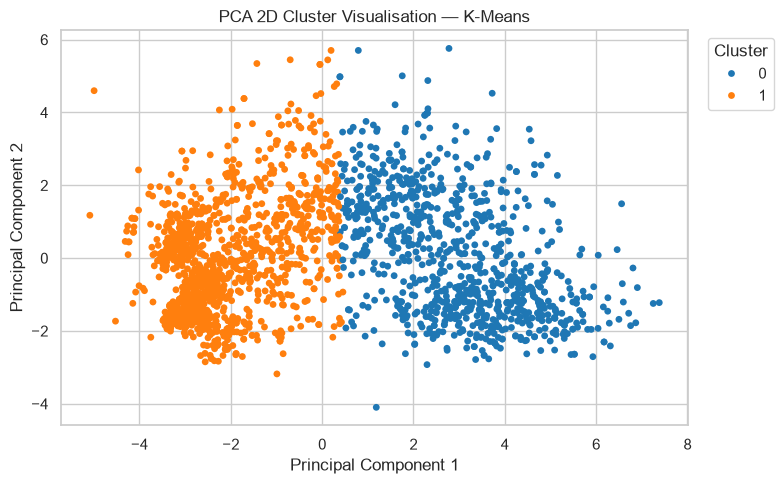

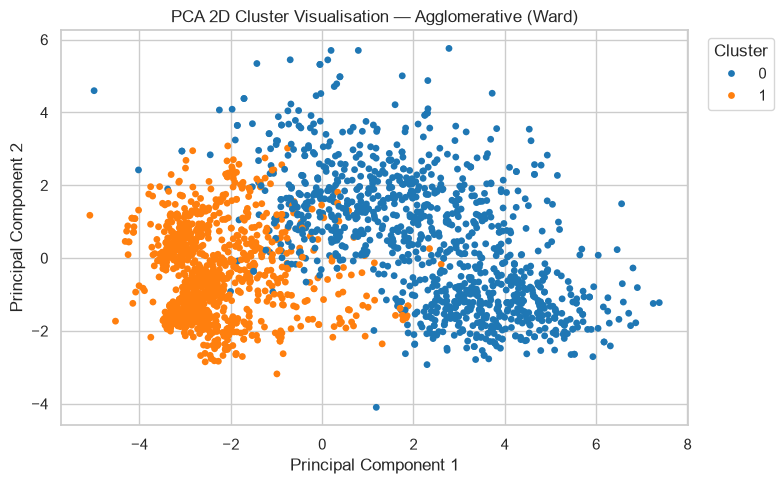

In [11]:
pca=PCA(n_components=2,random_state=RANDOM_STATE)
X_pca=pca.fit_transform(X)
print('PCA explained variance ratio:',pca.explained_variance_ratio_.round(4))
print('Total variance shown in 2D:',round(pca.explained_variance_ratio_.sum(),4))
for name,labels in cluster_labels.items():
    plt.figure(figsize=(8,5))
    sns.scatterplot(x=X_pca[:,0],y=X_pca[:,1],hue=labels,palette='tab10',s=24,linewidth=0,legend='full')
    plt.title(f'PCA 2D Cluster Visualisation — {name}')
    plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2')
    plt.legend(title='Cluster',bbox_to_anchor=(1.02,1),loc='upper left')
    plt.tight_layout(); plt.show()

## 11. t-SNE visualisation (K-Means)

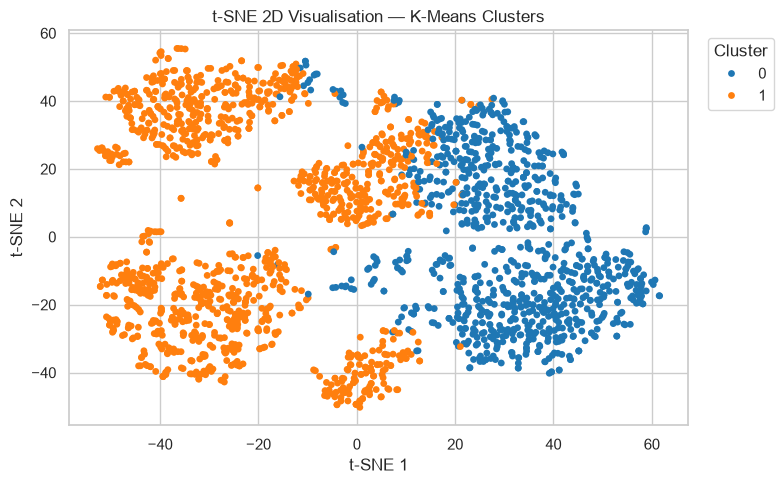

In [12]:
# t-SNE is a visualisation only; cluster labels still come from K-Means in the processed feature space.
tsne=TSNE(n_components=2,perplexity=30,init='pca',learning_rate='auto',random_state=RANDOM_STATE)
X_tsne=tsne.fit_transform(X)
plt.figure(figsize=(8,5))
sns.scatterplot(x=X_tsne[:,0],y=X_tsne[:,1],hue=kmeans_labels,palette='tab10',s=24,linewidth=0)
plt.title('t-SNE 2D Visualisation — K-Means Clusters')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2')
plt.legend(title='Cluster',bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout(); plt.show()

## 12. Interpret cluster profiles

In [13]:
# Profile clusters using the original, interpretable engineered features.
profile = features.copy()
profile['KMeans_Cluster'] = kmeans_labels
numeric_profile = profile.groupby('KMeans_Cluster').mean(numeric_only=True)
display(numeric_profile.round(2))

cluster_sizes = pd.Series(kmeans_labels).value_counts().sort_index()
cluster_size_table = pd.DataFrame({
    'Customers': cluster_sizes,
    'Percentage': (cluster_sizes / len(kmeans_labels) * 100).round(2)
})
display(cluster_size_table)



,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,TotalSpend,TotalPurchases,HouseholdChildren
KMeans_Cluster,,,,,,,,,,,,,,,,,,,
0,71515.80,0.07,0.44,49.38,599.57,54.30,351.37,77.27,56.28,75.06,2.06,5.82,5.22,8.54,3.78,59.12,1213.85,21.63,0.51
1,38441.36,0.71,0.56,48.91,93.29,6.35,35.54,9.20,6.25,21.90,2.51,2.85,0.84,3.83,6.41,55.82,172.54,10.04,1.27


,Customers,Percentage
0,932,41.61
1,1308,58.39


## 13. Conclusion

The analysis of 2,240 customer records identified two customer segments using K-Means clustering. K-Means performed better than Ward agglomerative clustering, achieving a silhouette score of 0.2973, Davies–Bouldin index of 1.4324, and Calinski–Harabasz index of 1003.3014.

The resulting clusters revealed differences in income and purchasing behaviour. Cluster 0 contained relatively higher-income, higher-spending customers, while Cluster 1 consisted of lower-income, lower-spending customers with more household children and frequent web visits. These profiles can support exploratory customer segmentation and targeted marketing strategies.

Although K-Means was the best-performing method among those evaluated, the moderate silhouette score indicates that cluster separation is limited. PCA and t-SNE visualisations help illustrate the results but may not fully preserve the original feature-space relationships. Further validation is recommended before applying these segments to real marketing decisions.

